# AP 155 Lab Exercise
---
## Exercise 12: Integrals

_Instructions_: 
- **Report figure**
    - See Problem 1: Log-log plot of absolute error vs $h$ for trapezoidal and Simpson rules.
- **Report discussion**
    - See Problem 1: Compare and analyze the integration error for both rules. Describe how the methods work and their advantages and disadvantages.
    - See Problem 2: Compare deterministic quadrature with a Monte Carlo estimate. Describe how the methods work and their advantages and disadvantages.
- **Code**: Complete the code and ensure it is functional, error-free, readable, and efficient (where needed). Include concise Markdown documentation highlighting the critical steps of your algorithm for each problem.

### Student Information
- _Full Name (Last Name, First Name)_: 
- _Student No._: 20XX-XXXXX
- _Section_: THR-TX-X

### Grading Information (c/o Lab Instructor)
- [Rubrics description link](https://drive.google.com/file/d/1BMSlPot2Mc7XLu0eo4S8I8gLBsIadbCL/view)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figure | XX | 20 |
| Report discussion | XX | 20|
| Code readability | XX | 20 |
| Code efficiency | XX | 20 | 
| Code appropriateness  | XX | 20 | 
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_ 

---
## Section 1: Report

### Report figure

<img src="figures/cat.jpg" alt="Alt text" width=45%> <img src="figures/cat.jpg" alt="Alt text" width=45%>


EDIT ME. See instruction above for what to include. Insert caption here, a short description what the figure illustrates. The syntax in markdown for putting a figure is `![Description](local_file_name.png)` or `<img src="/path/to_image.jpg" alt="Alt text" width=45%>`. Make sure the figure has complete elements.


### Report discussion

EDIT ME. See instruction above for what to include. Insert your discussions here. Discuss your key results with at most 150 words per question.

### Other comments
- EDIT ME
- A self reflection can be placed here.
- This portion is not graded.
- You may insert further questions here.


---
## Section 2: Code

In [50]:
import numpy as np
import matplotlib.pyplot as plt
import math

### Problem 0: Testing with an easy integral

Test the rectangle, trapezoidal, Simpson's rule, and Monte Carlo quadrature on an easy function first. Analytically solve the integral below and test whether the modular functions work.
$$ \int_0^\pi \sin(x)dx \tag{1}.$$

### Problem 1: Newton-Cotes quadrature and error scaling in nonlinear pendulum oscillations

For small angular displacements, a simple pendulum executes simple harmonic motion with a period 
$$T_0 = 2\pi\sqrt{L/g}. $$
However, for large initial angular amplitudes $\theta_0$, the exact period requires solving an incomplete elliptic integral of the first kind:
$$T(\theta_0) = 4 \sqrt{\frac{L}{g}} \int_{0}^{\pi/2} \frac{d\phi}{\sqrt{1 - k^2 \sin^2\phi}}$$
where $k = \sin\left(\frac{\theta_0}{2}\right)$. 

You will evaluate the dimensionless period ratio 
$$\frac{T}{T_0} = \frac{2}{\pi} \int_{0}^{\pi/2} \frac{d\phi}{\sqrt{1 - k^2 \sin^2\phi}}\tag{2}$$ using composite Newton-Cotes integration techniques.

Use the modular functions in Section 3, solve Eq. $(2)$ given $\theta_0=0.5\;\text{rad}$, $[a,b]=[0, \pi/2]$ using both the trapezoidal rule and Simpson's rule.

**REPORT FIGURE 1**
- Create a log-log plot resulting from the rectangle, trapezoid, and Simpson’s rules of evaluation of Eq. (3). For the absolute error use the `scipy` as the benchmark, i.e. absolute error$=|x_\text{integrated} - x_\text{scipy}|$.

**REPORT DISCUSSION 1**
- Differentiate the two methods and explain what the log-log error plot implies

#### Problem 1 code summary

Include a brief summary (2–3 sentences) at the bottom of your code outlining the purpose of the script and its core algorithm. Focus on explaining why you wrote the code this way and the reasoning behind your implementation choices.

### Problem 2: Work done by an oscillatory damped force (deterministic vs. Monte Carlo)

Consider the volume calculation of a $d$-dimensional unit hyperball embedded within a $d$-dimensional hypercube domain $\Omega = [-1, 1]^d$. The integrand is defined by the indicator function:$$f(\mathbf{x}) = \begin{cases} 1 & \text{if } \sum_{i=1}^d x_i^2 \le 1 \\ 0 & \text{otherwise} \end{cases} \tag{3}$$The exact volume $V_d$ of the unit hyperball is given by the multidimensional definite integral over $\Omega$:$$V_d = \int_{[-1, 1]^d} f(\mathbf{x}) \, d\mathbf{x} \tag{4}$$Using modular code, evaluate Eq. $(4)$ for dimension $d = 8$ (exact analytical volume $V_8 = \frac{\pi^4}{24} \approx 4.058712$)...

**REPORT DISCUSSION 2**
- Solve the function using MC quadrature
- (Optional): Try it with deterministic quadrature

In [57]:
import scipy.special as math_special

def exact_unit_ball_volume(d):
    """Analytical volume: V_d = pi^(d/2) / Gamma(d/2 + 1)"""
    return (np.pi ** (d / 2.0)) / math_special.gamma(d / 2.0 + 1)

In [58]:
exact_unit_ball_volume(2)

3.141592653589793

#### Problem 2 code summary

Include a brief summary (2–3 sentences) at the bottom of your code outlining the purpose of the script and its core algorithm. Focus on explaining why you wrote the code this way and the reasoning behind your implementation choices.

---
## Section 3: Notes

In [37]:
import numpy as np
import matplotlib.pyplot as plt
from math import pi
from scipy import integrate, interpolate

# Numpy recommends initializing the generator rather than
# using np.random directly. See docs for details:
# https://numpy.org/doc/stable/reference/random/index.html

rng = np.random.default_rng()

### Integration using `scipy`

In [1]:
from scipy.integrate import quad

# define the integrand
def integrand(x):
    return x**2

# integrate from 0 to 2
val, err = quad(integrand, 0, 2)

print(f"Integral value: {val}") 
print(f"Estimated error: {err}")

Integral value: 2.666666666666667
Estimated error: 2.960594732333751e-14


### Newton-Cotes methods

In [ ]:
import numpy as np

def f(x):
    return 1/np.sqrt(x**2 + 1)

In [21]:
def rectangle(f,a,b,n):
    h = (b-a)/(n-1)
    xs = a + np.arange(n-1)*h
    fs = f(xs)
    return h*np.sum(fs)

def trapezoid(f,a,b,n):
    h = (b-a)/(n-1)
    xs = a + np.arange(n)*h
    cs = np.ones(n); cs[0] = 0.5; cs[-1] = 0.5
    contribs = cs*f(xs)
    return h*np.sum(contribs)

def simpson(f,a,b,n):
    h = (b-a)/(n-1)
    xs = a + np.arange(n)*h
    cs = 2*np.ones(n)
    cs[1::2] = 4; cs[0] = 1; cs[-1] = 1
    contribs = cs*f(xs)
    return (h/3)*np.sum(contribs)

In [3]:
ans = np.log(1 + np.sqrt(2))
print(ans)
for integrator in (rectangle, trapezoid, simpson):
    print(integrator(f, 0., 1., 51), end=" ")

0.8813735870195429
0.8842907340357441 0.8813618018476096 0.8813735872550068 

### Adaptive integration

In [3]:
def adaptive(f,a,b,integrator,kmax = 20,tol = 1.e-12):
    functodenom = {rectangle:1, trapezoid:3, simpson:15}
    denom = functodenom[integrator]
    
    n = 2
    val = integrator(f,a,b,n)
    for k in range(kmax):
        nprime = 2*n-1
        valprime = integrator(f,a,b,nprime)
        err = abs(valprime-val)/denom
        err /= abs(valprime)
        print(nprime, valprime, err)
        if err<tol:
            break
        n, val = nprime, valprime
    else:
        valprime = None
    return valprime

ans = np.log(1 + np.sqrt(2))
print(ans); print("")
for integrator in (rectangle, trapezoid, simpson):
    print(adaptive(f, 0., 1., integrator)); print("")

0.8813735870195429

3 0.9472135954999579 0.055728090000841286
5 0.916142422786312 0.033915220975301544
9 0.8992189680174908 0.01882017102701063
17 0.8904114055046639 0.009891565245432775
33 0.8859212709638695 0.005068322308041195
65 0.8836546222074284 0.002565084479249227
129 0.8825159028886247 0.0012903102539869183
257 0.8819451945210681 0.0006471018506614681
513 0.8816595031619392 0.0003240382008069289
1025 0.8815165731886424 0.00016214099387806258
2049 0.8814450871285676 8.110097965111355e-05
4097 0.881409338830174 4.055811167264878e-05
8193 0.8813914633638882 2.0280961444329077e-05
16385 0.881382525301473 1.0140957142462958e-05
32769 0.8813780561879474 5.070597678496957e-06
65537 0.8813758216106051 2.5353286163347806e-06
131073 0.881374704316789 1.267671752616387e-06
262145 0.8813741456685948 6.338377372359589e-07
524289 0.8813738663441765 3.1691933359854855e-07
1048577 0.8813737266818862 1.584597839262419e-07
None

3 0.8739902907965947 0.007794480258544551
5 0.8795307704346305 0.0

### Romberg integration

In [ ]:
def prettyprint(row):
for elem in row:
print("")
print("{0:1.11f} ".format(elem),end="")
def richardson(Rprev, Rincurr0, i):
Rcurr = [Rincurr0]
for j in range(1, i+1):
val = (4**j*Rcurr[j-1] - Rprev[j-1])/(4**j - 1)
Rcurr.append(val)
return Rcurr
def romberg(f,a,b,imax = 20,tol = 1.e-8):
n = 2
val = trapezoid(f,a,b,n)
Rprev = [val]
#prettyprint(Rprev)
for i in range(1,imax):
nprime = 2*n-1
Rincurr0 = trapezoid(f,a,b,nprime)
Rcurr = richardson(Rprev, Rincurr0, i)
#prettyprint(Rcurr)
err = abs(Rprev[-1] - Rcurr[-1])/abs(Rcurr[-1])
valprime = Rcurr[-1]
if err < tol:
break
n = nprime
Rprev = Rcurr[:]
else:
valprime = None
return valprime
if name == ‘ main ’:
ans = np.log(1 + np.sqrt(2))
print(ans)
print(romberg(f,0.,1.))

### Monte Carlo

In [30]:
def montecarlo(f,a,b,n,option="uniform"):
    np.random.seed(314159)
    us = np.random.uniform(a, b, n)
    if option=="uniform":
        fs = f(us)
    else:
        c0 = 4 - 2*np.sqrt(2)
        c1 = -6 + 4*np.sqrt(2)
        xs = (-c0 + np.sqrt(2*c1*us + c0**2))/c1
        fs = f(xs)/(c0 + c1*xs)
    
    fbar, err = stats(fs)
    return (b-a)*fbar, (b-a)*err
    
def stats(fs):
    n = fs.size
    fbar = np.sum(fs)/n
    fsq = np.sum(fs**2)/n
    varfbar = (fsq - fbar**2)/(n - 1)
    return fbar, np.sqrt(varfbar)

for n in 10**np.arange(2,7):
    avu, erru = montecarlo(f, 0., 1., n)
    avi, erri = montecarlo(f, 0., 1., n, option="is")
    rowf = "{0:7d} {1:1.9f}{2:1.9f} {3:1.9f}{4:1.9f}"
    print(rowf.format(n, avu, erru, avi, erri))

    100 0.4787794150.025475052 0.4865378530.030971872
   1000 0.4656607510.007986678 0.4691778970.009559807
  10000 0.4640942200.002495727 0.4656928090.002967917
 100000 0.4600517570.000782468 0.4600610780.000929907
1000000 0.4595885070.000247592 0.4595322420.000294066


3.1596


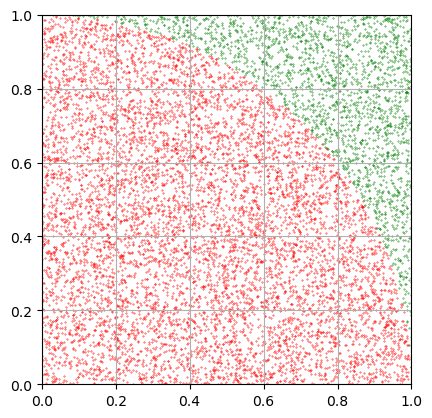

In [38]:
# Draw Nsamp points (xi, yi) from the box [0,1]x[0,1]
Nsamp = 10000
x = rng.random(size=Nsamp)
y = rng.random(size=Nsamp)

# Check which point falls within the quarter circle r=1 i.e.,
# sqrt(x^2 + y^2) <= 1. Numpy automatically does this 
# element-wise and will return a boolean array

r = np.sqrt(x**2 + y**2)
is_inside = (r <= 1)

# Taking the sum of the boolean array returns how many True
# is inside. Thus, the fraction of True's from the drawn points is:
inside_ratio = np.sum(is_inside)/Nsamp

# What is 4 times this ratio?
print(inside_ratio*4)

## Visualization
fig, ax = plt.subplots()
ax.scatter(x[is_inside], y[is_inside], s=0.1, c="red")
ax.scatter(x[~is_inside], y[~is_inside], s=0.1, c="green")
ax.set(xlim=[0,1], ylim=[0,1], aspect="equal")
ax.grid(True)

Let's try a more fun integral
$I = \int_\infty^\infty \frac{e^{-x^2}}{\sqrt{x^2 + 1}}dx$
> From Wolfram Alpha ... $I\approx 1.52411$

What does it look like?

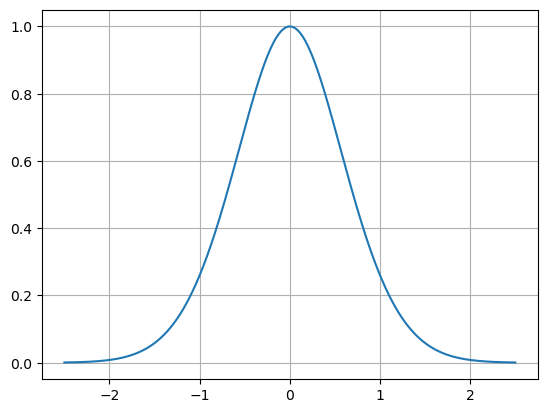

In [39]:
x = np.linspace(-2.5, 2.5, 1000)
curve = np.exp(-x**2)/np.sqrt(x**2 + 1)

fig, ax = plt.subplots()
ax.plot(x, curve)
ax.grid(True)

If we naively apply the principle above, we just need to draw numbers $x_i$ from $(-\infty, \infty)$, draw another number $y_i$ from $[0, \infty)$, then check if $y_i$ is underneath $f(x_i)$. The ratio of points $(x_i, y_i)$ that fall within the curve will give the area under the curve as a proportion of the rectangle covering it.
- Would drawing from `rng.uniform` from $(-\infty, \infty)$ make sense?
- Do I really have to draw points $y_i$ above 1 if the height of the curve doesn't go beyond that anyway?
- Bulk of the area falls within $−1<x<1$ where the points are likely to fall inside. Beyond that, getting underneath the curve is very unlikely, *but still contributes to the area.*

Consider the form:
$$I=\int_{-\infty}^\infty f(x) p(x) dx $$ where with random variable $X$ with probability distribution $p(x)$, we're finding the expectation $\langle f(x) \rangle_X$.

In [40]:
# Draw from N(0, 1/sqrt(2)) ~ (1/sqrt(pi))*exp(-x^(-2))
x = rng.normal(0, 1/np.sqrt(2), size=100000)
# Take the average. f has to cancel the (1/sqrt(pi)) from p(x)
expect = np.mean(np.sqrt(np.pi)/(np.sqrt(1 + x**2)))
print(expect)


my_int = lambda x: np.exp(-x**2)/np.sqrt(1 + x**2)
quad_out, err = integrate.quad(my_int, -np.inf, np.inf)
print(quad_out)

1.5242931690618449
1.5241093857739092


But what if I only want to integrate over $[1,5]$?

Look at Eq. 7.192 and Eq. 7.211 in Gezerlis (p. 543). First term is the one we did above

In [41]:
N = 100000

x = rng.normal(0, 1/np.sqrt(2), size=N)
# x = x[(x >= 1) * (x <= 5)]

fs = np.sqrt(np.pi)/(np.sqrt(1 + x**2))
fbar = np.sum(fs)/N
fsq = np.sum(fs**2)/N
varfbar = (fsq - fbar**2)/(N-1)

# bmina = 5 - 1


my_int = lambda x: np.exp(-x**2)/np.sqrt(1 + x**2)
quad_out, err = integrate.quad(my_int, 1, 5)
print(quad_out)

0.08520888517416615


In [42]:
x = np.linspace(1e-6, 10, 100)

p_x = np.exp(-x)

cdf_px = np.cumsum(p_x)/np.sum(p_x)
inv_cdf = interpolate.interp1d(cdf_px, x)

draw_nums = rng.uniform(min(cdf_px), max(cdf_px), 100000)

exp_draws = inv_cdf(draw_nums)

o = exp_draws #I'm lazy
vals = (o + o**2)/np.sqrt(o)

np.mean(vals)


# plt.hist(exp_draws, bins=100)
# plt.show()

2.219282986179471

9.42477796076938

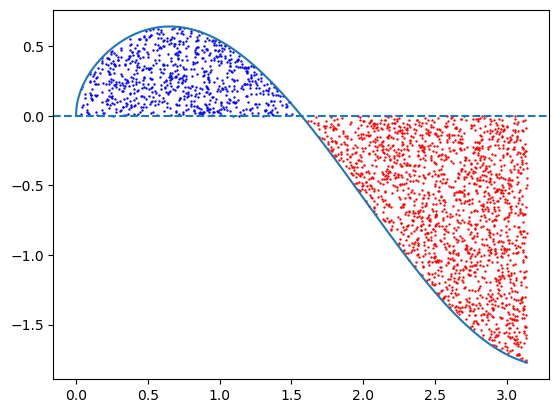

In [44]:
x = np.linspace(0, np.pi, 1000)

integrand = lambda x: np.cos(x) * np.sqrt(x)
plt.plot(x, integrand(x))


Nsamp = 10000
x_i = rng.uniform(0, np.pi, Nsamp)
y_i = rng.uniform(-2, 1, Nsamp) # arbitrary, where I think the curve is still inside

is_inside = y_i < integrand(x_i)
is_pos = y_i > 0
is_neg = y_i < 0

plt.scatter(x_i[is_inside*is_pos], y_i[is_inside*is_pos], c="blue", s=0.5)
plt.scatter(x_i[~is_inside*is_neg], y_i[~is_inside*is_neg], c="red", s=0.5)

plt.axhline(0, linestyle="--")

total_area = (np.pi - 0) * (1 - (-2))

## Q: Which contributes positive/negative area? How many dots overall?
## what is the overall are of the uniform distribution where the 
## points were drawn from.
total_area